# Лабораторная работа № 4. Логические методы классификации
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** изучение принципов построения информационных систем с использованием логических методов классификации.

**Задачи:** освоить алгоритмы на основе решающих списков и деревьев; изучить параметры логической классификации и её модификации.

**Данные:** Iris для примера; прежний RCAEval RE2-OB для индивидуального задания.

Работа выполнена по лабораторной № 4 методички *Practicum_AI_Methods.pdf*, с. 42–52.

## 1. Локальный запуск
Используем прежнее окружение Conda `rcaeval-ai` с Python 3.11 и scikit-learn 1.7. В VS Code выбираем его ядро и нажимаем **Run All**. Ноутбук работает из корня проекта и из `notebooks/`.

RCAEval читается из сохранённых файлов первой работы. Таблицы и графики сохраняются в папке этой лабораторной внутри `reports/`.

Подключаем библиотеки.

In [1]:
from pathlib import Path
from importlib.metadata import version
from itertools import combinations
from urllib.request import urlopen
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, export_graphviz
from sklearn.metrics import make_scorer
from matplotlib.patches import Patch

Задаём пути к данным и результатам.

In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab04'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 17
sns.set_theme(style='whitegrid')

Выводим и сохраняем версии библиотек.

In [3]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn', 'scipy']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
numpy             2.2.6
pandas            2.3.3
matplotlib       3.10.9
seaborn          0.13.2
scikit-learn      1.7.2
scipy            1.17.1
Name: Версия, dtype: object

163

Определяем функцию сохранения и показа графиков.

In [4]:
def save_show(fig, name):
    fig.savefig(FIGURES / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Дерево состоит из проверок вида «признак ≤ порог». `max_depth` ограничивает число уровней проверок. `max_features` — число признаков, рассматриваемых при поиске **одного разделения**, а не число столбцов входной таблицы.

В методичке график `1 − accuracy` назван MSE. Здесь сохраняем смысл её примера и подписываем его как **долю ошибок классификации**. Для бинарных меток 0/1 это также численно равно MSE меток. Для строковых видов Iris настоящая MSE не определена.

`gini` показывает смешанность классов в узле, `samples` — число обучающих строк, `value` — их распределение по классам. В используемой версии scikit-learn на рисунке с `proportion=False` показываются количества. Ответ листа — класс с наибольшим количеством строк.

Определяем функцию показа дерева в PNG.

In [5]:
def show_tree(model, features, names, filename):
    labels = {'checkoutservice_cpu': 'CPU', 'checkoutservice_mem': 'Память',
              'checkoutservice_latency-50': 'Медианная задержка', 'checkoutservice_socket': 'Socket'}
    short_features = [labels.get(name, name) for name in features]
    fig, ax = plt.subplots(figsize=(max(12, model.get_n_leaves() * 2.5),
                                    max(5, model.get_depth() * 1.8)))
    plot_tree(model, feature_names=short_features, class_names=names,
              filled=True, rounded=True, precision=3, fontsize=10, ax=ax)
    ax.set_title('Проверки и ответы дерева решений')
    save_show(fig, filename)

Определяем функцию построения двумерного среза выбранной модели.

In [6]:
def boundary_slice(model, training, features, names, ax):
    a, b = features
    gx = np.linspace(training[a].min(), training[a].max(), 150)
    gy = np.linspace(training[b].min(), training[b].max(), 150)
    xx, yy = np.meshgrid(gx, gy)
    grid = pd.DataFrame(np.tile(training.median().to_numpy(), (xx.size, 1)), columns=training.columns)
    grid[a], grid[b] = xx.ravel(), yy.ravel()
    regions = pd.Series(model.predict(grid)).map(dict(zip(model.classes_, range(len(names)))))
    ax.contourf(xx, yy, regions.to_numpy().reshape(xx.shape),
                levels=np.arange(len(names) + 1) - 0.5,
                cmap=ListedColormap(sns.color_palette('pastel', len(names))), alpha=0.8)
    ax.set(xlabel=a, ylabel=b)

На рисунках границ меняются два признака, а остальные фиксируются на медианах **обучающей** части. Цвет фона показывает ответы именно выбранной модели с полным набором признаков. Это срез её правила; он не показывает все возможные сочетания остальных признаков. На таких срезах не оцениваем accuracy.

## 2. Учебная задача: Iris
### 2.1. Загрузка и hold-out
Повторяем пример методички: pandas, дерево с глубиной 5 и двумя признаками при разделении, hold-out, CV, GridSearchCV, экспорт дерева, новые запросы и границы решений. В файле Iris нет заголовка, поэтому задаём названия четырёх размеров цветка и вида.

Загружаем прежний файл Iris.

In [7]:
iris_features = ['sepal length', 'sepal width', 'petal length', 'petal width']
iris_path = ROOT / 'data/raw/iris/iris.data'
iris = pd.read_csv(iris_path, header=None, names=iris_features + ['answer'])

Печатаем первые строки.

In [8]:
display(iris.head())
print('Цветков:', len(iris))

,sepal length,sepal width,petal length,petal width,answer
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


Цветков: 150


Разделяем Iris и обучаем дерево с параметрами примера.

In [9]:
Xi_dev, Xi_test, yi_dev, yi_test = train_test_split(
    iris[iris_features], iris.answer, test_size=0.3, stratify=iris.answer, random_state=12)
iris_user = DecisionTreeClassifier(max_depth=5, max_features=2, random_state=21).fit(Xi_dev, yi_dev)
print('Hold-out accuracy:', accuracy_score(yi_test, iris_user.predict(Xi_test)))

Hold-out accuracy: 0.9777777777777777


Отложенные 30% цветков далее не участвуют в выборе параметров. Предварительный hold-out показывает работу параметров из примера; итоговое выбранное дерево проверим отдельно на той же отложенной части.

### 2.2. Подбор глубины и двух параметров

Вычисляем CV для глубины от 1 до 19 при max_features = 2.

In [10]:
iris_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
iris_depth_rows = []
for depth in range(1, 20):
    model = DecisionTreeClassifier(max_depth=depth, max_features=2, random_state=21)
    scores = cross_val_score(model, Xi_dev, yi_dev, cv=iris_cv, scoring='accuracy')
    iris_depth_rows.append({'max_depth': depth, 'error': 1 - scores.mean()})
iris_depth_table = pd.DataFrame(iris_depth_rows)
display(iris_depth_table)

,max_depth,error
0,1,0.388182
1,2,0.105455
2,3,0.058182
3,4,0.058182
4,5,0.077273
5,6,0.068182
6,7,0.077273
7,8,0.077273
8,9,0.077273
9,10,0.077273


Строим график зависимости ошибки от глубины.

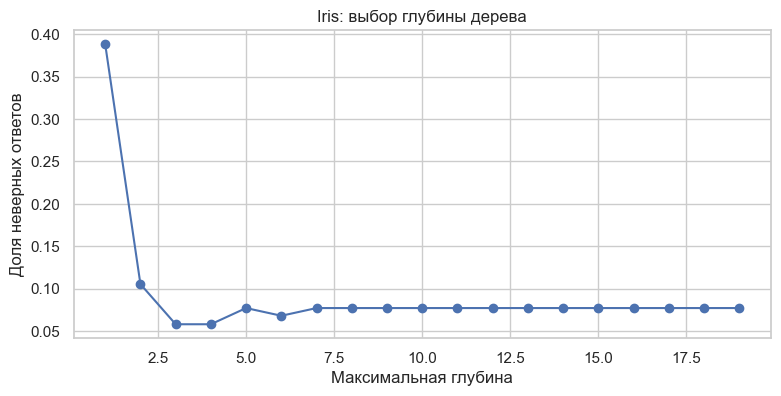

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(iris_depth_table.max_depth, iris_depth_table.error, marker='o')
ax.set(title='Iris: выбор глубины дерева', xlabel='Максимальная глубина', ylabel='Доля неверных ответов')
save_show(fig, '01_iris_depth.png')

Ниже расположены более удачные глубины. Большая глубина не гарантирует улучшения: дерево может запомнить отдельные цветки. Здесь при каждом значении глубины меняется только этот параметр; число рассматриваемых признаков равно двум.

Подбираем глубину и число признаков через GridSearchCV.

In [12]:
iris_grid = GridSearchCV(DecisionTreeClassifier(random_state=21),
    {'max_depth': list(range(1, 20)), 'max_features': [1, 2, 3]},
    cv=iris_cv, scoring='accuracy', n_jobs=1)
iris_grid.fit(Xi_dev, yi_dev)
iris_model = iris_grid.best_estimator_
print('Лучшие параметры:', iris_grid.best_params_)
print('Средняя accuracy CV:', iris_grid.best_score_)
print('Fold = 10; candidate = 19 × 3 = 57; fit = 10 × 57 = 570 (+ одно итоговое обучение).')

Лучшие параметры: {'max_depth': 3, 'max_features': 2}
Средняя accuracy CV: 0.9418181818181818
Fold = 10; candidate = 19 × 3 = 57; fit = 10 × 57 = 570 (+ одно итоговое обучение).


**Fold** — число частей CV. **Candidate** — одно сочетание параметров. **Fit** — одно обучение на части данных. GridSearchCV сравнивает 57 сочетаний и выполняет 570 обучений при проверке, затем обучает лучшее сочетание на всей части подбора. При равенстве выбирается первое сочетание в заданном порядке.

Сохраняем DOT и показываем выбранное дерево Iris в PNG.

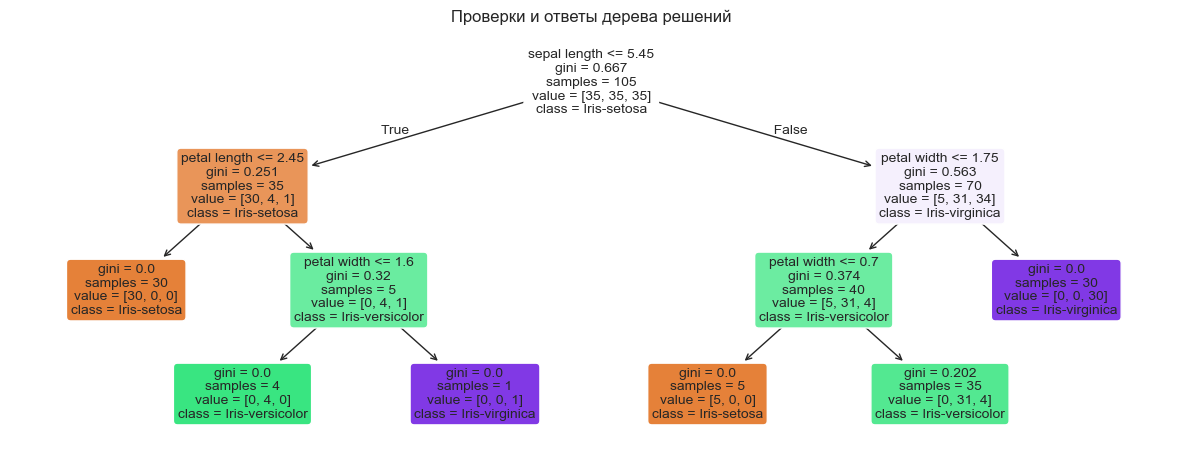

In [13]:
iris_names = list(iris_model.classes_)
export_graphviz(iris_model, out_file=str(REPORT / 'iris_tree.dot'), feature_names=iris_features,
                class_names=iris_names, filled=True, rounded=True)
show_tree(iris_model, iris_features, iris_names, '02_iris_tree.png')

Начинаем читать дерево сверху. Если условие выполняется, идём влево; иначе вправо. В листе виден выбранный вид цветка. PNG строится локально через `plot_tree`, без внешнего сайта и установки Graphviz.

Для читаемости на рисунках сокращены имена метрик: CPU, Память, Медианная задержка и Socket. В модели остаются прежние столбцы.

Вводим новые размеры цветков и получаем ответы выбранного дерева.

In [14]:
new_iris = pd.DataFrame([[1.2, 1.0, 2.8, 1.2], [5.12, 3.53, 1.42, 0.21],
                         [6.52, 3.03, 5.42, 2.11]], columns=iris_features)
display(new_iris.assign(Ответ=iris_model.predict(new_iris)))
print('Итоговая hold-out accuracy:', accuracy_score(yi_test, iris_model.predict(Xi_test)))

,sepal length,sepal width,petal length,petal width,Ответ
0,1.20,1.00,2.80,1.20,Iris-versicolor
1,5.12,3.53,1.42,0.21,Iris-setosa
2,6.52,3.03,5.42,2.11,Iris-virginica


Итоговая hold-out accuracy: 0.9777777777777777


Первая строка — запрос из методички, остальные введены для демонстрации изменения ответа. Это не добавленные реальные наблюдения. Первая строка выходит за обычный диапазон размеров Iris, поэтому её ответ не подтверждает качество на настоящих цветках.

Строим срезы границ Iris по шести разным парам размеров.

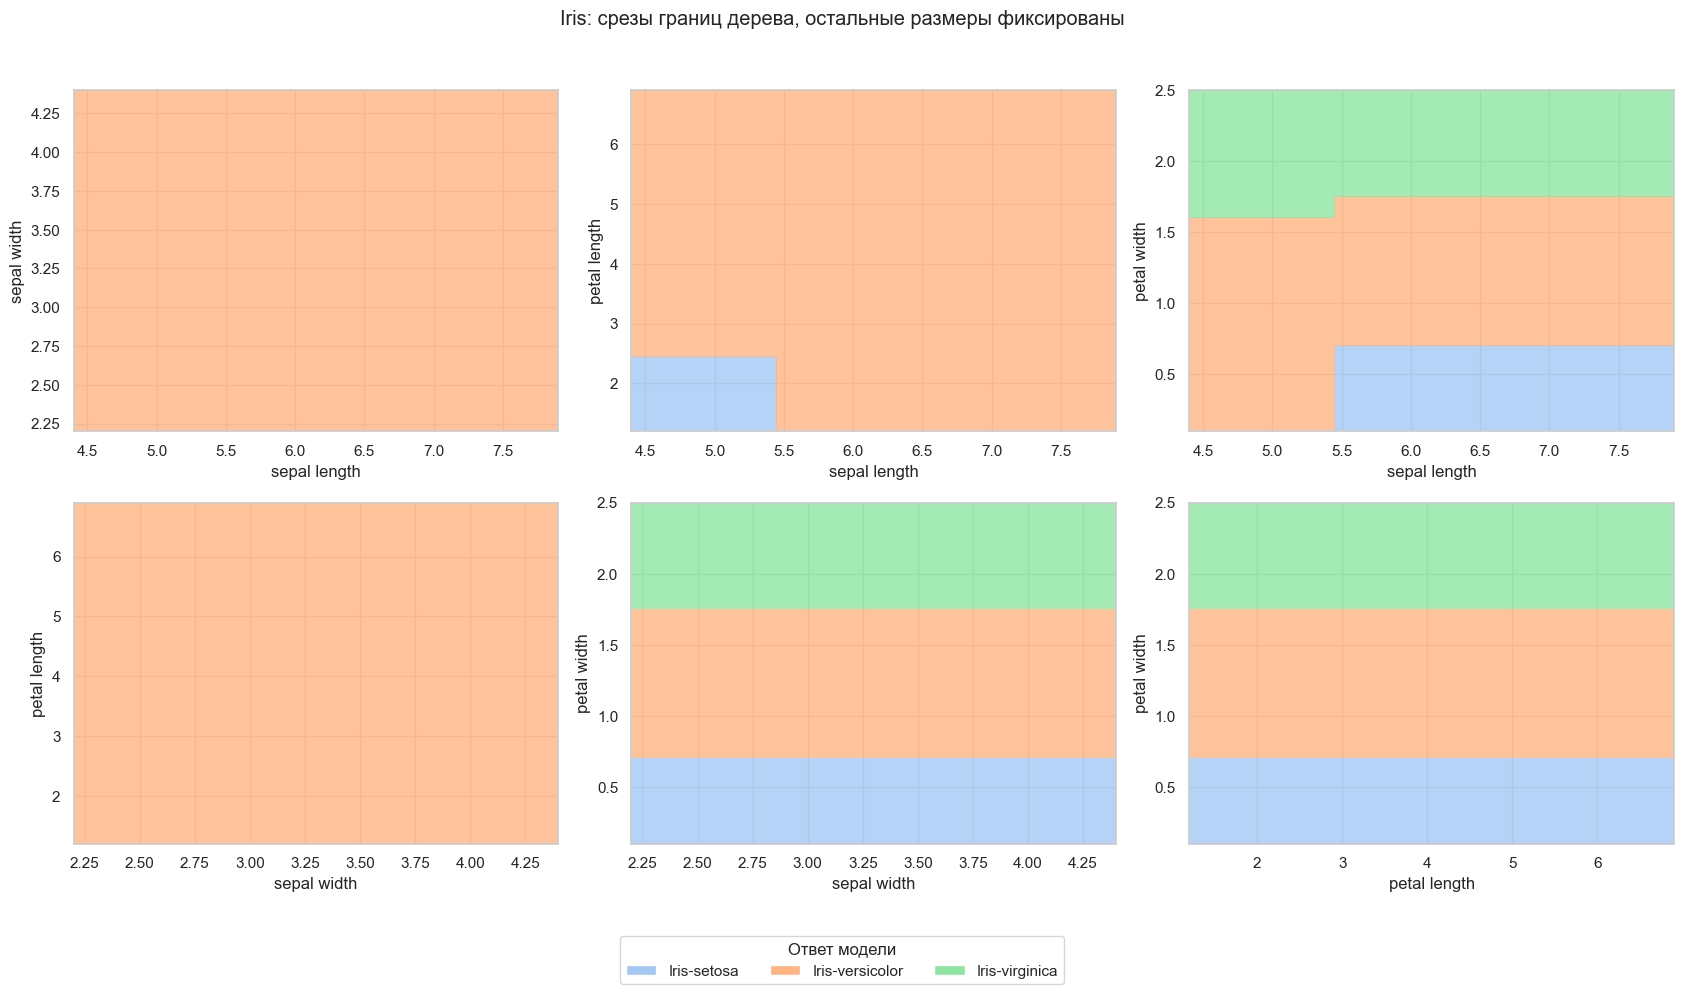

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, pair in zip(axes.flat, combinations(iris_features, 2)):
    boundary_slice(iris_model, Xi_dev, pair, iris_names, ax)
fig.suptitle('Iris: срезы границ дерева, остальные размеры фиксированы')
fig.legend(handles=[Patch(facecolor=color, label=name) for color, name in
                    zip(sns.color_palette('pastel', len(iris_names)), iris_names)],
           loc='lower center', ncol=len(iris_names), title='Ответ модели')
fig.tight_layout(rect=(0, 0.08, 1, 0.96))
save_show(fig, '03_iris_boundaries.png')

Цвет каждой области означает предсказанный вид. Линии параллельны осям, потому что дерево проверяет один признак за раз. Панели показывают разные пары размеров при фиксированных остальных размерах. Это помогает прочитать правило, но не заменяет проверку на отложенных цветках.

## 3. Индивидуальное задание: RCAEval
### 3.1. Данные и разделение

Каждая строка — измерение в один момент времени. Класс 0 означает период до внесения сбоя, класс 1 — начиная с внесения. Модель определяет период по четырём метрикам `checkoutservice`. Время и метка периода не входят в признаки. Метка «после» не является отдельной проверкой неисправности каждой строки.

Это прежний CPU-сценарий RCAEval RE2-OB (Online Boutique). Из одного сценария нельзя оценить обнаружение всех видов сбоев.

**Согласование датасета с преподавателем:** ____________________  
**Дата:** ____________________

Читаем имя прежнего сценария.

In [16]:
selection = json.loads((ROOT / 'reports/lab01/selected_case.json').read_text(encoding='utf-8'))
case = selection['case']
case_dir = ROOT / 'data/raw/rcaeval' / case

Загружаем сохранённые метрики и время внесения сбоя.

In [17]:
metrics_path = case_dir / 'metrics.parquet'
inject_path = case_dir / 'inject_time.txt'
df = pd.read_parquet(metrics_path)
inject_time = int(inject_path.read_text(encoding='utf-8').strip())

Печатаем первые строки и сведения о данных.

In [18]:
display(df.head())
print('Сценарий:', case, '| Сервис:', selection['root_cause_service'], '| Сбой:', selection['fault'])
print('Строк:', len(df), '| Метрик:', df.shape[1] - 1)
print('Момент внесения:', pd.to_datetime(inject_time, unit='s', utc=True))

,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,paymentservice_cpu,productcatalogservice_cpu,recommendationservice_cpu,...,adservice_latency-90,cartservice_latency-90,checkoutservice_latency-90,currencyservice_latency-90,emailservice_latency-90,frontend_latency-90,paymentservice_latency-90,productcatalogservice_latency-90,recommendationservice_latency-90,shippingservice_latency-90
0,1705353846,0.685023,2.216467,0.215886,19.035876,0.279166,6.724489,0.52931,2.636831,2.474853,...,0.004604,0.004993,0.850000,0.110638,0.0046,0.819737,0.008955,0.004418,0.009670,0.004576
1,1705353847,0.685023,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.636858,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008955,0.004423,0.009672,0.004576
2,1705353848,0.582707,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.584059,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008636,0.004423,0.009672,0.004576
3,1705353849,0.625903,2.216467,0.380058,19.106596,0.279166,6.724489,0.52931,3.250317,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576
4,1705353850,0.613414,2.216467,0.380058,19.106596,0.279166,5.572668,0.52931,3.250317,2.474853,...,0.004594,0.006304,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576


Сценарий: re2ob_checkoutservice_cpu_1 | Сервис: checkoutservice | Сбой: cpu
Строк: 1441 | Метрик: 72
Момент внесения: 2024-01-15 21:36:06+00:00


Выбираем признаки и формируем классы.

In [19]:
rca_features = ['checkoutservice_cpu', 'checkoutservice_mem',
                'checkoutservice_latency-50', 'checkoutservice_socket']
X = df[rca_features].copy()
y = (df['time'] >= inject_time).astype(int)
class_names = ['До внесения', 'После внесения']

Показываем назначение признаков, пропуски и число строк каждого класса.

In [20]:
display(pd.DataFrame({'Признак': rca_features,
                      'Описание': ['CPU', 'Память', 'Медианная задержка', 'Показатель socket'],
                      'Тип': X.dtypes.to_numpy(), 'Пропуски': X.isna().sum().to_numpy()}))
display(y.value_counts().sort_index().rename(index=dict(enumerate(class_names))).rename('Строк'))

,Признак,Описание,Тип,Пропуски
0,checkoutservice_cpu,CPU,float64,0
1,checkoutservice_mem,Память,float64,0
2,checkoutservice_latency-50,Медианная задержка,float64,0
3,checkoutservice_socket,Показатель socket,float64,0


time
До внесения       720
После внесения    721
Name: Строк, dtype: int64

В выбранных четырёх числовых признаках нет пропусков. Исходные значения не изменяем. Точные единицы отдельных метрик в локальном файле не указаны, поэтому сохраняем исходную шкалу.

Оставляем целые минутные участки для итоговой проверки.

In [21]:
groups = ((df['time'] - df['time'].min()) // 60).astype(int)
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(outer_cv.split(X, y, groups))
X_dev, X_test = X.iloc[dev_idx], X.iloc[test_idx]
y_dev, y_test = y.iloc[dev_idx], y.iloc[test_idx]
groups_dev = groups.iloc[dev_idx]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
print('Для подбора:', len(X_dev), '| Для итоговой проверки:', len(X_test))

Для подбора: 1141 | Для итоговой проверки: 300


Соседние по времени измерения похожи. Поэтому при CV и итоговой проверке записи одной минуты остаются вместе. Все параметры подбираем на `X_dev`. Отложенные `X_test` используем после выбора. Это проверка в рамках одного эксперимента, а не прогноз будущего или проверка на новом сбое.

### 3.2. Параметры пользователя и PNG дерева — пункт 2.1

Задаём параметры и обучаем дерево.

In [22]:
MAX_DEPTH_USER = 3
MAX_FEATURES_USER = 2
user_tree = DecisionTreeClassifier(max_depth=MAX_DEPTH_USER, max_features=MAX_FEATURES_USER,
                                   random_state=SEED).fit(X_dev, y_dev)

Показываем дерево с заданными параметрами.

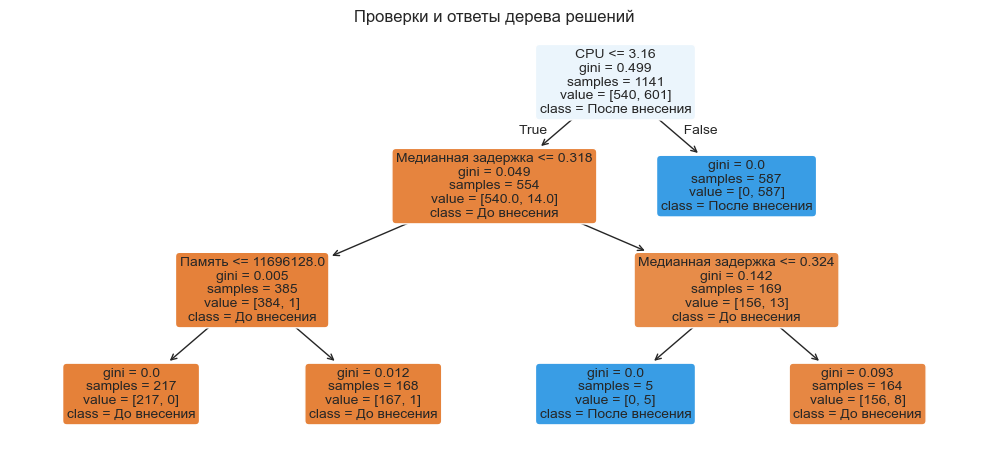

In [23]:
show_tree(user_tree, rca_features, class_names, '04_rca_user_tree.png')

Параметры можно изменить в предыдущей ячейке. Сначала изучаем структуру, затем сравниваем качество CV. Дереву не требуется масштабирование: пороги выбираются внутри каждого признака.

Для читаемости на рисунках сокращены имена метрик: CPU, Память, Медианная задержка и Socket. В модели остаются прежние столбцы.

### 3.3. CV при разных глубинах — пункт 2.2

Считаем среднюю ошибку по пяти частям для разных глубин.

In [24]:
depth_rows = []
for depth in range(1, 20):
    model = DecisionTreeClassifier(max_depth=depth, max_features=MAX_FEATURES_USER, random_state=SEED)
    scores = cross_val_score(model, X_dev, y_dev, groups=groups_dev, cv=cv, scoring='accuracy')
    depth_rows.append({'max_depth': depth, 'error': 1 - scores.mean()})
depth_table = pd.DataFrame(depth_rows)
display(depth_table)

,max_depth,error
0,1,0.011667
1,2,0.011667
2,3,0.015833
3,4,0.073692
4,5,0.039963
5,6,0.065939
6,7,0.039167
7,8,0.039167
8,9,0.039167
9,10,0.039167


Строим график ошибки для разных глубин.

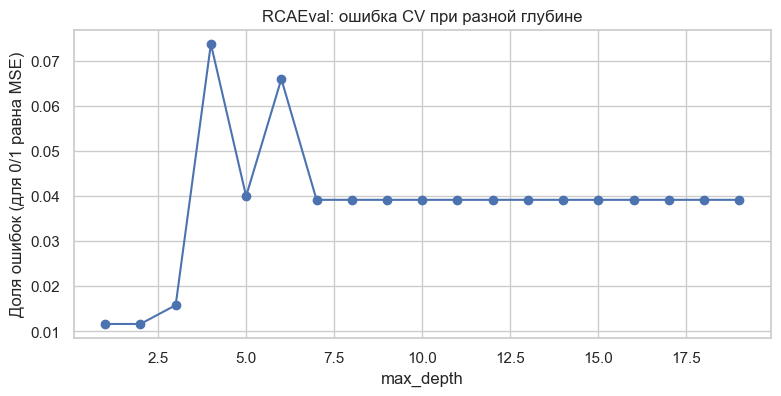

In [25]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(depth_table.max_depth, depth_table.error, marker='o')
ax.set(title='RCAEval: ошибка CV при разной глубине', xlabel='max_depth', ylabel='Доля ошибок (для 0/1 равна MSE)')
save_show(fig, '05_rca_depth.png')

Чем ниже точка, тем меньше перепутанных периодов. По этому графику видно влияние глубины при фиксированном числе признаков. Если несколько глубин дают одинаковую ошибку, усложнение дерева не улучшило эту проверку.

### 3.4. CV при разном числе признаков — пункт 2.3

Считаем ошибку при max_features от 1 до 4.

In [26]:
feature_rows = []
for count in range(1, 5):
    model = DecisionTreeClassifier(max_depth=MAX_DEPTH_USER, max_features=count, random_state=SEED)
    scores = cross_val_score(model, X_dev, y_dev, groups=groups_dev, cv=cv, scoring='accuracy')
    feature_rows.append({'max_features': count, 'error': 1 - scores.mean()})
feature_table = pd.DataFrame(feature_rows)
display(feature_table)

,max_features,error
0,1,0.011667
1,2,0.015833
2,3,0.011667
3,4,0.011667


Строим график ошибки для разного числа признаков.

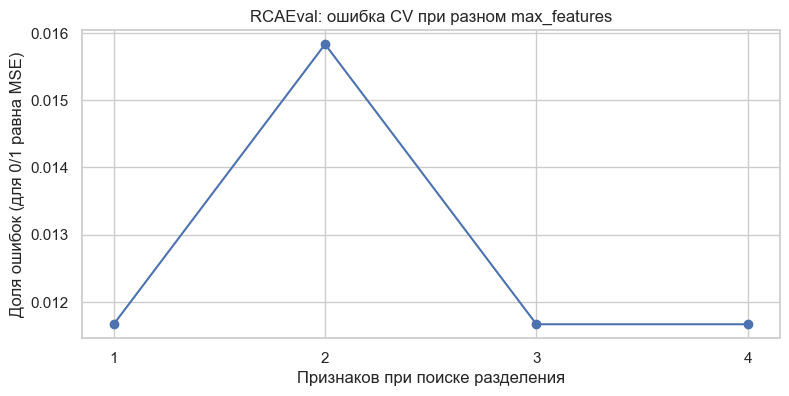

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(feature_table.max_features, feature_table.error, marker='o')
ax.set(title='RCAEval: ошибка CV при разном max_features', xlabel='Признаков при поиске разделения',
       ylabel='Доля ошибок (для 0/1 равна MSE)', xticks=[1, 2, 3, 4])
save_show(fig, '06_rca_features.png')

При одном признаке поиск разделения сильнее ограничен. При четырёх доступны все выбранные метрики. Здесь глубина фиксирована, поэтому этот график не даёт совместного лучшего сочетания двух параметров.

### 3.5. Совместный подбор и демонстрация — пункт 2.4

Перебираем сочетания параметров по CV.

In [28]:
rca_grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
    {'max_depth': list(range(1, 20)), 'max_features': [1, 2, 3, 4]},
    scoring='accuracy', cv=cv, n_jobs=1)
rca_grid.fit(X_dev, y_dev, groups=groups_dev)
grid_results = pd.DataFrame(rca_grid.cv_results_)
best_rows = grid_results.loc[grid_results.mean_test_score == grid_results.mean_test_score.max()]
display(best_rows[['param_max_depth', 'param_max_features', 'mean_test_score']])
rca_model = rca_grid.best_estimator_
print('Выбрано:', rca_grid.best_params_)
print('Средняя accuracy CV:', rca_grid.best_score_)

,param_max_depth,param_max_features,mean_test_score
1,1,2,0.988333
2,1,3,0.988333
3,1,4,0.988333
4,2,1,0.988333
5,2,2,0.988333
6,2,3,0.988333
7,2,4,0.988333
8,3,1,0.988333
10,3,3,0.988333
11,3,4,0.988333


Выбрано: {'max_depth': 1, 'max_features': 2}
Средняя accuracy CV: 0.9883333333333333


Лучшие параметры дали наибольшую среднюю accuracy на пяти частях. При равенстве используется первое сочетание сетки: меньшая глубина, затем меньшее число признаков. Это понятное правило без выбора по итоговой проверке. Оно не означает, что другие равные варианты хуже.

Проверяем выбранное дерево на отложенных данных и показываем его ответы.

In [29]:
prediction = rca_model.predict(X_test)
final_accuracy = accuracy_score(y_test, prediction)
final_mse = mean_squared_error(y_test, prediction)
print(f'Accuracy: {final_accuracy:.3f}; MSE бинарных меток: {final_mse:.3f}')
demo = X_test.iloc[[0, len(X_test)//2, -1]].copy()
demo['Настоящий период'] = y_test.loc[demo.index].map(dict(enumerate(class_names)))
demo['Ответ модели'] = pd.Series(rca_model.predict(demo[rca_features]), index=demo.index).map(dict(enumerate(class_names)))
display(demo)

Accuracy: 1.000; MSE бинарных меток: 0.000


,checkoutservice_cpu,checkoutservice_mem,checkoutservice_latency-50,checkoutservice_socket,Настоящий период,Ответ модели
0,0.215886,11702272.0,0.243182,9.0,До внесения,До внесения
630,0.461238,12001280.0,0.221875,9.0,До внесения,До внесения
1319,19.988612,16564224.0,0.317308,11.0,После внесения,После внесения


### 3.6. Итоговое дерево в PNG — пункт 2.5

Сохраняем и показываем выбранное дерево.

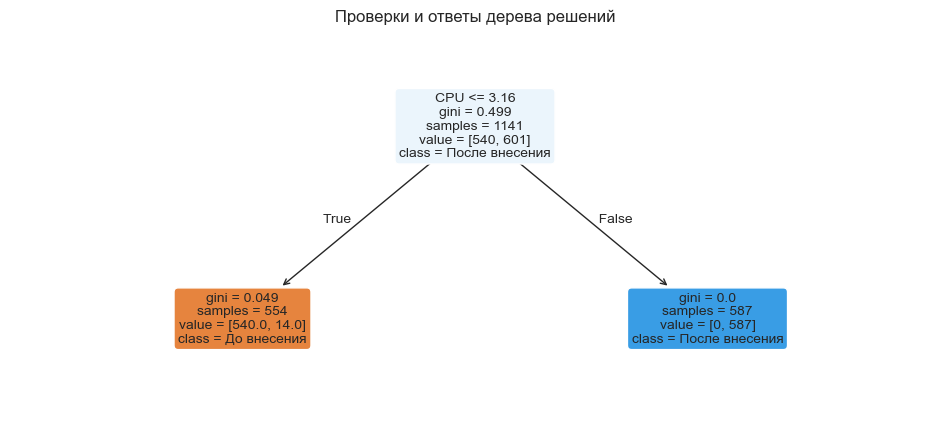

|--- checkoutservice_cpu <= 3.16
|   |--- class: 0
|--- checkoutservice_cpu >  3.16
|   |--- class: 1



In [30]:
show_tree(rca_model, rca_features, class_names, '07_rca_best_tree.png')
print(export_text(rca_model, feature_names=rca_features))

Текст под рисунком содержит те же проверки. Для новой строки выполняем условия сверху вниз и доходим до класса в листе. Порог относится к исходной шкале указанной метрики.

### 3.7. Границы полученной модели — пункт 2.6

Строим срезы границ по всем шести парам метрик.

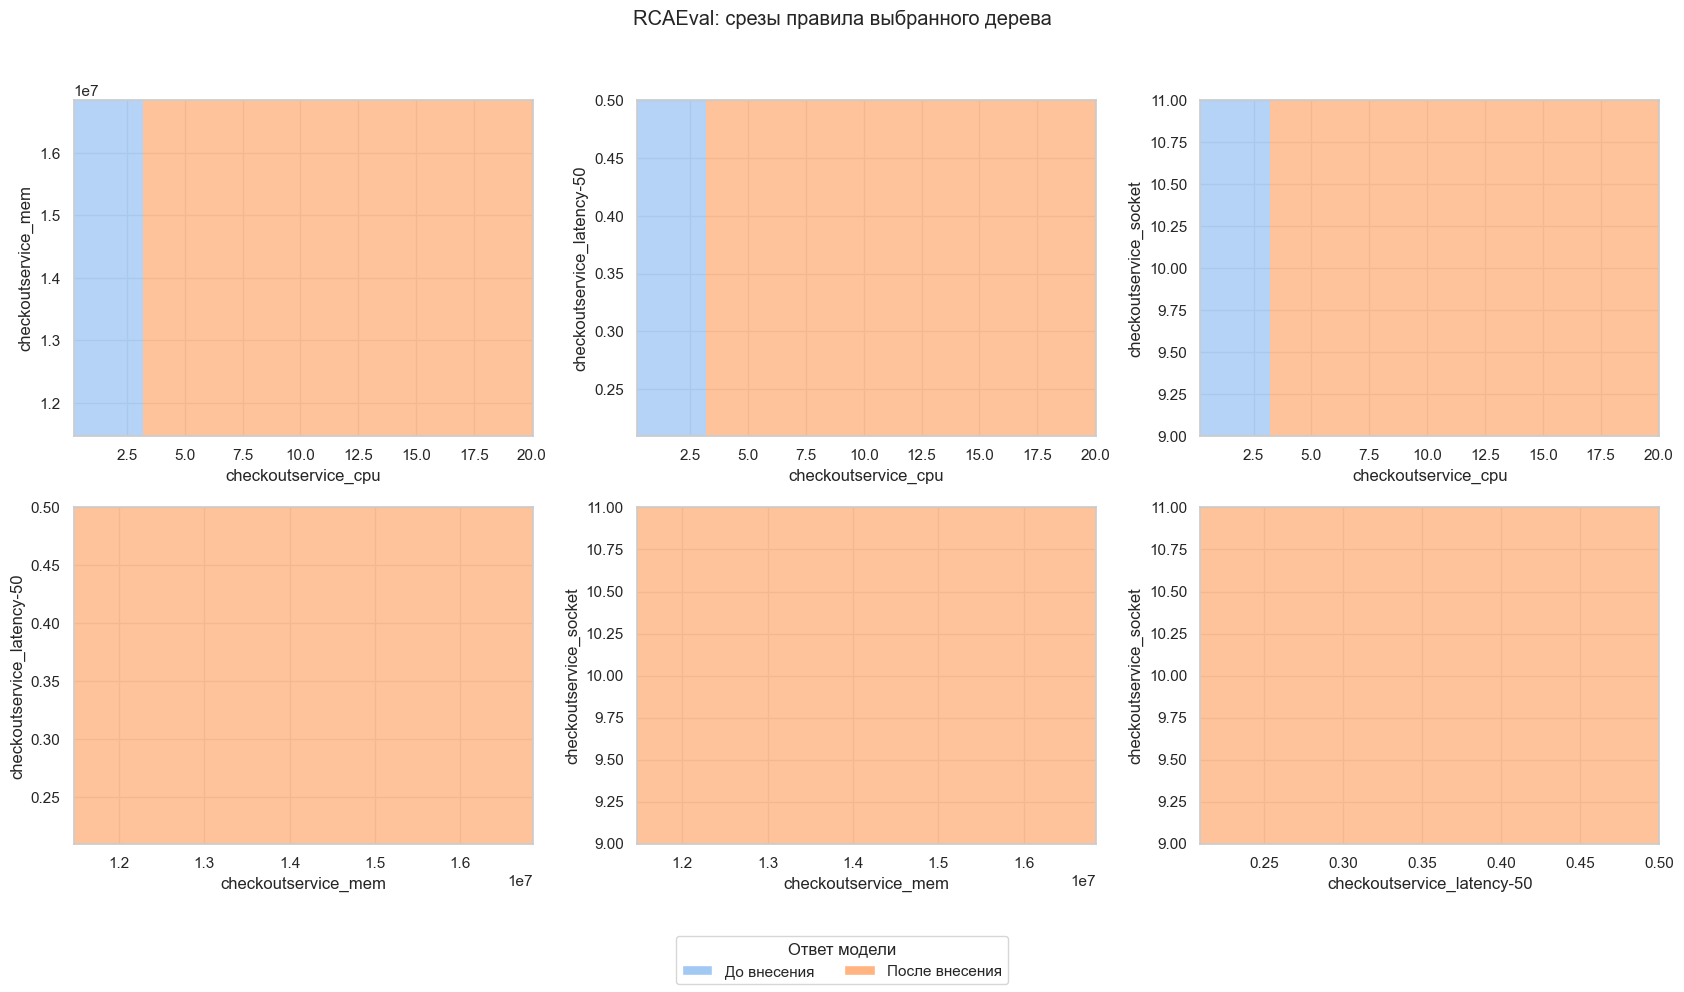

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, pair in zip(axes.flat, combinations(rca_features, 2)):
    boundary_slice(rca_model, X_dev, pair, class_names, ax)
fig.suptitle('RCAEval: срезы правила выбранного дерева')
fig.legend(handles=[Patch(facecolor=color, label=name) for color, name in
                    zip(sns.color_palette('pastel', len(class_names)), class_names)],
           loc='lower center', ncol=len(class_names), title='Ответ модели')
fig.tight_layout(rect=(0, 0.08, 1, 0.96))
save_show(fig, '08_rca_boundaries.png')

Каждый фон показывает период, выбранный деревом для двух меняющихся метрик. Остальные метрики равны медианам обучающей части. Если фон одной панели одноцветный, при этих фиксированных значениях смена двух выбранных показателей не меняет ответ. Подписи осей содержат имена и исходные шкалы метрик.

### 3.8. Решающий список и модификации

Показываем ответы дерева как последовательность условий «если — иначе».

In [32]:
def decision_list(row, model):
    node = 0
    checks = []
    while model.tree_.children_left[node] != -1:
        feature = rca_features[model.tree_.feature[node]]
        threshold = model.tree_.threshold[node]
        left = row[feature] <= threshold
        checks.append(f'{feature} <= {threshold:.3f}: {left}')
        node = model.tree_.children_left[node] if left else model.tree_.children_right[node]
    answer = int(model.classes_[model.tree_.value[node].argmax()])
    return checks, class_names[answer]
checks, answer = decision_list(X_test.iloc[0], rca_model)
print('\n'.join(checks))
print('Ответ:', answer)

checkoutservice_cpu <= 3.160: True
Ответ: До внесения


Это последовательное выполнение условий дерева для одной строки. Ниже превращаем все пути до листьев в список правил и применяем его как отдельную функцию предсказания. Самостоятельное обучение решающего списка в этой работе не выполняется.

Преобразуем пути выбранного дерева в список правил.

In [33]:
def collect_rules(node=0, conditions=()):
    tree = rca_model.tree_
    if tree.children_left[node] == -1:
        answer = int(rca_model.classes_[tree.value[node].argmax()])
        return [(conditions, answer)]
    feature, threshold = rca_features[tree.feature[node]], tree.threshold[node]
    left_rules = collect_rules(tree.children_left[node], conditions + ((feature, threshold, True),))
    right_rules = collect_rules(tree.children_right[node], conditions + ((feature, threshold, False),))
    return left_rules + right_rules
rules = collect_rules()
for conditions, answer in rules:
    text = ' и '.join(f'{name} {"<=" if left else ">"} {threshold:.3f}' for name, threshold, left in conditions)
    print(f'Если {text}, ответ: {class_names[answer]}')

Если checkoutservice_cpu <= 3.160, ответ: До внесения
Если checkoutservice_cpu > 3.160, ответ: После внесения


Применяем список правил к новой для модели строке.

In [34]:
def predict_by_rules(row):
    for conditions, answer in rules:
        if all((row[name] <= threshold) if left else (row[name] > threshold)
               for name, threshold, left in conditions):
            return answer
    return int(y_dev.mode().iloc[0])
list_prediction = np.array([predict_by_rules(row) for _, row in X_test.iterrows()])
print('Accuracy списка правил:', accuracy_score(y_test, list_prediction))
print('Все ответы совпали с деревом:', np.array_equal(list_prediction, prediction))

Accuracy списка правил: 1.0
Все ответы совпали с деревом: True


Правила проверяются по порядку; возвращается ответ первого выполненного правила. Все условия одного правила связаны словом «и». В конце задан ответ по умолчанию. Здесь правила получены из дерева: для полных числовых строк всегда выполняется один путь, поэтому ответы списка и дерева совпадают. Это другой способ применения уже найденных закономерностей, без отдельного обучения списка.

Сравниваем критерии Gini и энтропии с выбранными ограничениями дерева.

In [35]:
mod_rows = []
for criterion in ['gini', 'entropy']:
    model = DecisionTreeClassifier(**rca_grid.best_params_, criterion=criterion, random_state=SEED)
    scores = cross_val_score(model, X_dev, y_dev, groups=groups_dev, cv=cv, scoring='accuracy')
    mod_rows.append({'criterion': criterion, 'accuracy': scores.mean()})
display(pd.DataFrame(mod_rows))

,criterion,accuracy
0,gini,0.988333
1,entropy,0.988333


Gini и энтропия по-разному оценивают смешанность классов при поиске порога. Ограничение глубины, увеличение минимального размера листа и удаление лишних ветвей — способы сделать дерево проще. Здесь сравнение критериев выполнено на части подбора.

Формируем и сохраняем простой текст результатов.

In [36]:
analysis = (f'Изучил дерево решений на Iris и прежнем сценарии {case}. '
            f'По пяти частям CV выбраны параметры {rca_grid.best_params_}. '
            f'На отложенных данных верно определён период для {(prediction == y_test).sum()} из {len(y_test)} строк ({final_accuracy:.1%}). '
            'Построил деревья, графики ошибок и срезы границ. Научился читать условия дерева и выполнять их по порядку. '
            'Результат относится к одному эксперименту; для других сбоев нужна отдельная проверка.')
display(Markdown(analysis))
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
depth_table.to_csv(REPORT / 'depth_cv.csv', index=False)
feature_table.to_csv(REPORT / 'features_cv.csv', index=False)
grid_results.to_csv(REPORT / 'grid_cv.csv', index=False)
summary = {'case': case, 'best_params': rca_grid.best_params_, 'cv_accuracy': rca_grid.best_score_,
           'test_accuracy': final_accuracy, 'test_mse': final_mse, 'test_rows': len(y_test),
           'iris_best_params': iris_grid.best_params_, 'figures': sorted(p.name for p in FIGURES.glob('*.png'))}
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

Изучил дерево решений на Iris и прежнем сценарии re2ob_checkoutservice_cpu_1. По пяти частям CV выбраны параметры {'max_depth': 1, 'max_features': 2}. На отложенных данных верно определён период для 300 из 300 строк (100.0%). Построил деревья, графики ошибок и срезы границ. Научился читать условия дерева и выполнять их по порядку. Результат относится к одному эксперименту; для других сбоев нужна отдельная проверка.

514

Сохраняем сведения об исходных файлах.

In [37]:
source_files = [iris_path, metrics_path, inject_path]
sources = {'rcaeval': selection, 'sha256': {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in source_files}}
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')

971